# TOVIS (*TO*nal *VIS*ualization toolbox): _Feature Extraction_
Johannes Zeitler and Meinard Müller, 2026

**Neural backends:** Install the `transcription` extra (`pip install "tovis[transcription]"`) and obtain compatible model checkpoints separately; they are not included with TOVIS. This notebook expects `checkpoint_OnsetsAndFrames.pt` and `checkpoint_deepChroma.pt` in the repository-root `checkpoints/` folder. Place the files there or edit the `transcription_checkpoint` paths below to match your locations. Neural inference uses the CPU by default and may be slow. To run without neural transcription, use `backends = ["IIR", "STFT", "CQT"]`; these backends need neither checkpoints nor PyTorch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os

from tovis.feature import compute_chromagram_from_file
from tovis.visualization import plot_chromagram, overlay_measure_annotations
from tovis.utils import read_csv

Specify BPSD directory and load annotations

In [2]:
BPSD_DIR = os.path.join("data", "BPSD")

piece = "Beethoven_Op014No2-01"
version = "WK64"

ann_audio_measure = read_csv(os.path.join(BPSD_DIR, "2_Annotations", "ann_audio_measure", piece + "_" + version + ".csv"))

We first compute tonal features from audio recordings. In MIR, a popular choice is "chroma", or "pitch class", features. There are different methods to extract features, some based on signal processing (IIR, STFT, CQT), and others based on deep learning models. In the following, we will compare five methods for chroma extraction from audio. 

To obtain a temporally smooth feature representation, we apply a temporal smoothing filter (in our case: 1 second) to every estimated feature matrix. The features are then interpolated to exactly match a desired output feature rate (in our case: 10 Hz).

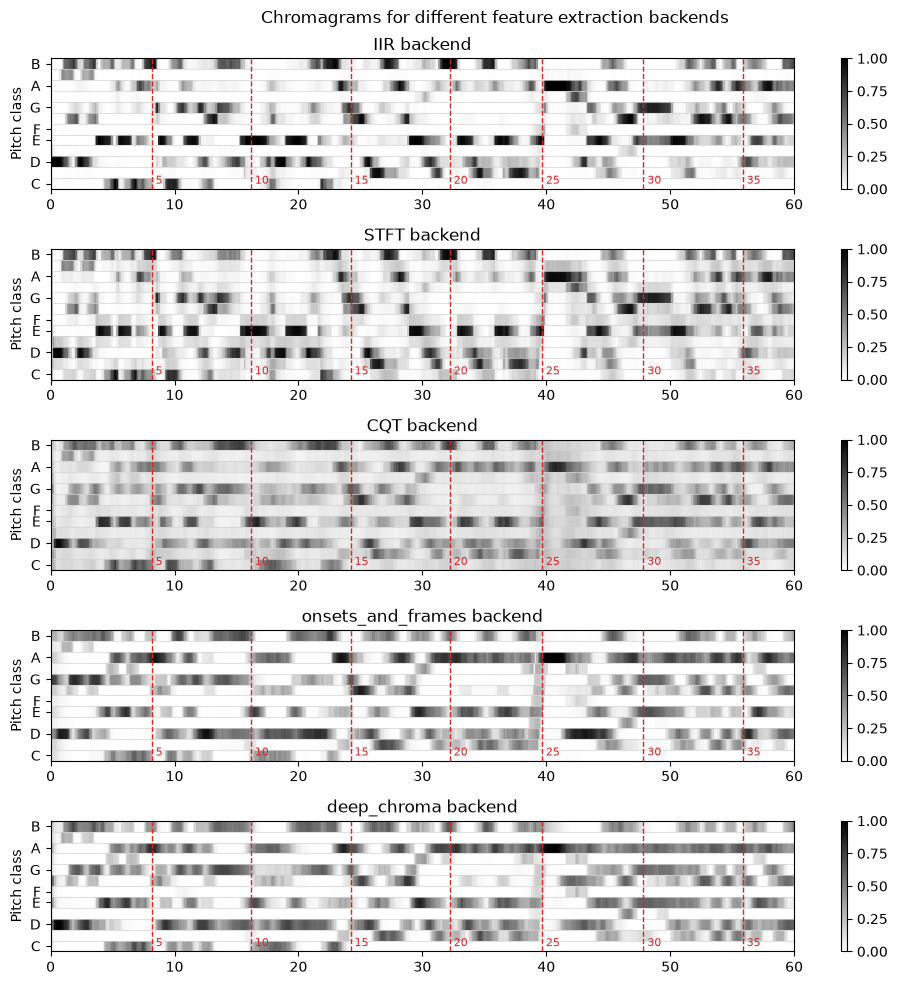

In [4]:
backends = ["IIR", "STFT", "CQT", "onsets_and_frames", "deep_chroma"]

fig, ax = plt.subplots(len(backends),1, figsize=(10, len(backends)*2))
for i, backend in enumerate(backends):
    if backend == "onsets_and_frames":
        transcription_checkpoint = os.path.join("../", "checkpoints", "checkpoint_OnsetsAndFrames.pt")
    elif backend == "deep_chroma":
        transcription_checkpoint = os.path.join("../", "checkpoints", "checkpoint_deepChroma.pt")
    else:
        transcription_checkpoint = None
    chromagram, sr_chromagram = compute_chromagram_from_file(os.path.join(BPSD_DIR, "1_Audio", piece + "_" + version + ".mp3"), 
                                                            backend=backend,
                                                            transcription_checkpoint=transcription_checkpoint,
                                                            start_time=0,
                                                            end_time=60,
                                                            smoothing_length_seconds=1,
                                                            output_feature_rate=10)
    
    plot_chromagram(chromagram, feature_rate=sr_chromagram, ax=ax[i], title="%s backend"%(backend), xlabel=None, show_natural_pitch_labels=True, clim=[0,1])

for ax_ in ax:
    overlay_measure_annotations(ann_audio_measure,ax=ax_, measure_annotation_hop=5)

fig.suptitle("Chromagrams for different feature extraction backends")
fig.tight_layout()
plt.show()